# Projeto de Previsão Econômica com Agente Assistivo 
Desenvolver um sistema de coleta, tratamento e modelagem de dados econômicos brasileiros (IPCA e SELIC), com geração de projeções mensais até 2030 e suporte de um agente assistivo para análise e interpretação dos resultados.

## Importações

In [7]:
import requests
import datetime
import nbformat
import pandas as pd
import matplotlib.pyplot as plt

from threading import Thread   
from scipy.stats import zscore
from flask import Flask, jsonify, request
from statsmodels.tsa.stattools import adfuller     
from statsmodels.tsa.statespace.sarimax import SARIMAX 
from nbconvert.preprocessors import ExecutePreprocessor

## Chamada da API

In [8]:
# chamada do caderno api.ipynb
%run api.ipynb

API de indicadores rodando! Acesse http://127.0.0.1:5000/indicadores
 * Serving Flask app 'api'
 * Debug mode: off


 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:5000
 * Running on http://192.168.15.11:5000
Press CTRL+C to quit


Status code: 200


## Chamada do MODELO SARIMA IPCA

In [18]:
# chamada do modelo_sarima_ipca.ipynb
%run modelo_sarima_ipca.ipynb

## Chamada do MODELO ARIMA SELIC

In [28]:
# chamada do modelo_arima_selic.ipynb
%run modelo_arima_selic.ipynb

## Chamada dos Cálculos Financeiros BACEN

Estatística ADF: -6.954932461606928
p-valor: 9.482313183648058e-10
Conclusão: Série estacionária (rejeita H0)
                               SARIMAX Results                                
Dep. Variable:                  valor   No. Observations:                  121
Model:               SARIMAX(1, 0, 1)   Log Likelihood                 -41.246
Date:                Mon, 16 Feb 2026   AIC                             88.492
Time:                        03:43:29   BIC                             96.829
Sample:                    01-01-2016   HQIC                            91.878
                         - 01-01-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9186      0.042     22.012      0.000       0.837       1.000
ma.L1         -0.4672

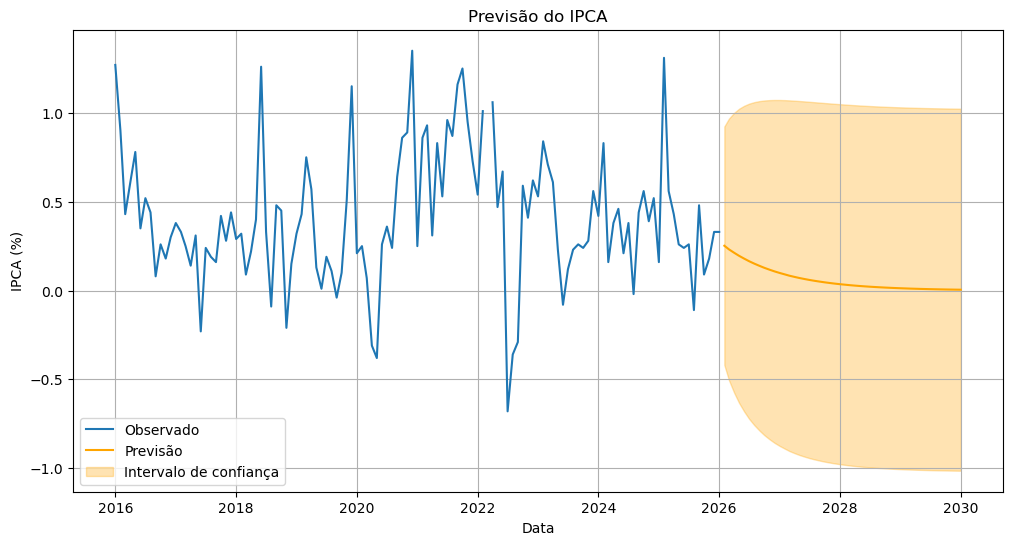

Teste ADF - Série em nível
Estatística ADF: -2.665557082460158
p-valor: 0.08019037214926139
Conclusão: Série não estacionária
                               SARIMAX Results                                
Dep. Variable:                  valor   No. Observations:                  122
Model:               SARIMAX(1, 1, 0)   Log Likelihood                 604.823
Date:                Mon, 16 Feb 2026   AIC                          -1205.645
Time:                        03:43:29   BIC                          -1200.070
Sample:                    01-01-2016   HQIC                         -1203.381
                         - 02-01-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.4184      0.074      5.683      0.000       0.274       0.563
sigma

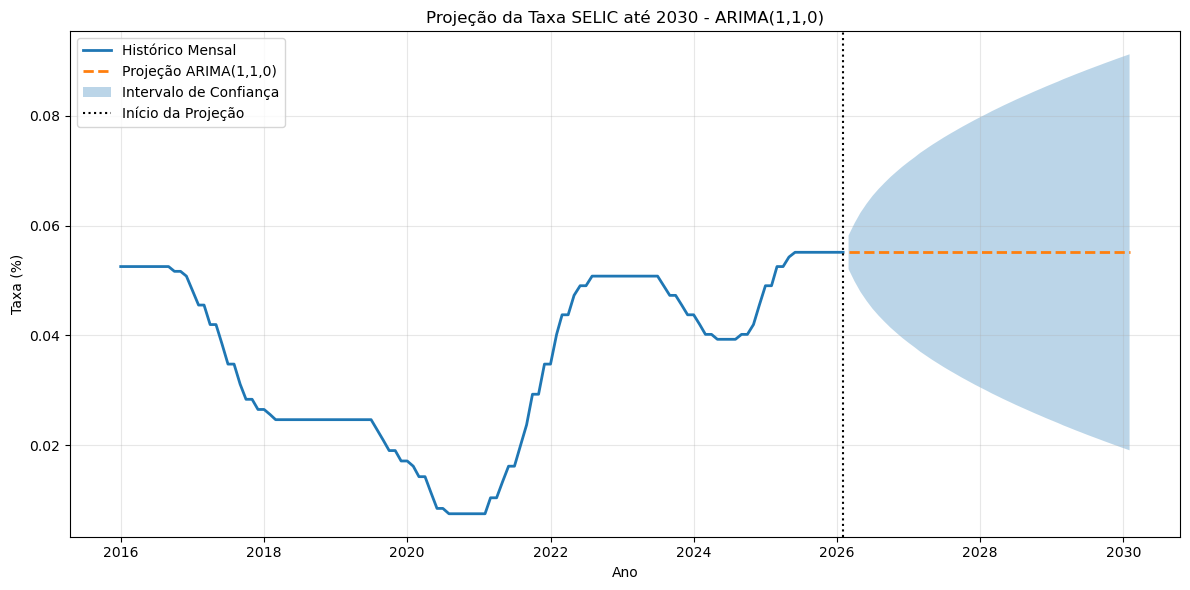

In [85]:
# chamada do caderno calc_finance_bacen.ipynb
%run calc_finance_bacen.ipynb

# Tranformações necessárias antes dos cálculos

## Substituindo os valores nulos das colunas limite_superior e limite_inferior por valor

In [99]:
# defininfo nome do df
df_preench_vl_null = df_concat_resultado_indicadores

# Para a coluna 'limite_inferior':
df_preench_vl_null['limite_inferior'] = df_preench_vl_null['limite_inferior'].where(
    # Mantém o valor original quando NÃO for NaN
    df_preench_vl_null['limite_inferior'].notna(),

    # Quando for NaN, substitui pelo valor da coluna 'valor'
    df_preench_vl_null['valor']
)

# Para a coluna 'limite_superior':
df_preench_vl_null['limite_superior'] = df_preench_vl_null['limite_superior'].where(
    # Mantém o valor original quando NÃO for NaN
    df_preench_vl_null['limite_superior'].notna(),

    # Mantém o valor original quando NÃO for NaN
    df_preench_vl_null['valor']
)

## Pivot de algumas colunas

In [113]:
df_pivot_col_final = (
    df_preench_vl_null
        .reset_index()
        .rename(columns={'index': 'data'})
        .assign(data=lambda x: pd.to_datetime(x['data']))
        .melt(
            id_vars=['data', 'indicador'],
            value_vars=['valor', 'limite_inferior', 'limite_superior'],
            var_name='cenarios',
            value_name='vl_taxa'
        )
        # Renomeia os valores da coluna 'cenarios'
        .replace({
            'cenarios': {
                'valor': 'base',
                'limite_superior': 'otimista',
                'limite_inferior': 'pessimista'
            }
        })
        #.set_index('data')
        #.sort_index()
        #.rename_axis(None)
        .sort_values('data')   # ordena mantendo como coluna
)


# Cálculos Econômicos

## Juros Real
#### Métrica central de postura monetária.

## Volatilidade do Juros Real
#### Mede instabilidade da postura monetária.

## Acumulado 12 meses IPCA
#### Pressão inflacionária anualizada.

## Média móvel 12 meses SELIC
#### Postura monetária sustentada.

## Volatilidade 12 meses IPCA
#### Risco inflacionário.

## Média do período 2026–2030
#### Resumo comparativo de cenários.

In [114]:
resultado = df_pivot_col_final.query(
    "'2026-01-01' <= data <= '2031-05-01'"
)
resultado.head(20)

,data,indicador,cenarios,vl_taxa
913,2026-01-01,SELIC,otimista,0.055131
576,2026-01-01,IPCA,pessimista,0.330000
577,2026-01-01,SELIC,pessimista,0.055131
240,2026-01-01,IPCA,base,0.330000
241,2026-01-01,SELIC,base,0.055131
912,2026-01-01,IPCA,otimista,0.330000
242,2026-02-01,IPCA,base,0.252155
914,2026-02-01,IPCA,otimista,0.923476
579,2026-02-01,SELIC,pessimista,0.055131
578,2026-02-01,IPCA,pessimista,-0.419165
